In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

df = pd.read_csv("Titanic dataset.csv")



# Titanic Dataset – Exploratory Data Analysis (EDA)

## 1. Project Overview

The Titanic dataset contains information about passengers who were aboard the RMS Titanic. This project focuses on analysing passenger demographics, travel information, and survival outcomes.

Using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn, we will perform data cleaning, exploratory data analysis, and data visualization to identify meaningful patterns and insights from the dataset.

## 2. Project Objectives

- Understand the structure and characteristics of the dataset.
- Identify and handle missing values and duplicate records.
- Perform data cleaning and preprocessing.
- Analyse passenger demographics and travel characteristics.
- Explore the factors associated with passenger survival.
- Create meaningful visualizations to communicate findings.
- Summarize key insights from the analysis.



## 3. Initial Data Exploration

In this section, we will perform an initial examination of the dataset to understand its structure, dimensions, column names, and data distribution.

This step will help us identify the different variables available and assess the overall quality of the data before proceeding with data cleaning.


In [3]:

df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S



### Initial Observations

After examining the first five records, the following observations were made:

1. PassengerId appears to be a unique identifier and may not contribute directly to analytical insights.
2. The Name column contains passenger names with different titles and formats, which may require further examination.
3. The Age column is stored as float64. This is acceptable because age values may contain decimal points and missing values.
4. The Ticket column contains ticket identification information that may be useful for further analysis.
5. The Cabin column appears to have a significant number of missing values and requires further investigation.

No columns will be removed at this stage. Decisions regarding data retention and transformation will be made after examining the complete dataset and understanding the analytical relevance of each variable.



### 3.1 Checking the Last Five Records

The last five records are examined to understand how the dataset ends and to check whether the structure and format of the records remain consistent throughout the dataset.


In [4]:

df.tail()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,0,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C



### Observations – Last Five Records

The examination of the last five records reveals that missing values are present in the Age and Cabin columns. The Ticket column also contains values in different formats, including numeric and alphanumeric entries. The Fare column contains decimal values.

These observations indicate that certain columns may require further data quality checks and preprocessing before conducting the analysis.



### 3.2 Dataset Dimensions

In this step, we will examine the dimensions of the dataset to determine the total number of passenger records and the number of variables available for analysis.


In [5]:
df.shape

(418, 12)


### Observations – Dataset Dimensions

The dataset consists of 418 rows and 12 columns, representing 418 passenger records and 12 variables.

Each row represents an individual passenger, while the columns contain information related to passenger identification, demographics, ticket class, travel details, and survival status.

The dataset provides a structured foundation for further data exploration and analysis.



### 3.3 Dataset Information and Data Types

In this step, we will examine the overall structure of the dataset using the info() method. This will help us understand the data types of individual columns, identify missing values through non-null counts, and assess the memory usage of the dataset.

Understanding these characteristics is essential before performing data cleaning and preprocessing.


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 56.1 KB



### Observations – Dataset Information

The dataset contains 418 entries and 12 columns, with a memory usage of approximately 56.1 KB.

The info() method reveals the following:

1. The Age column contains 332 non-null values, indicating 86 missing entries.
2. The Fare column contains 417 non-null values, indicating 1 missing entry.
3. The Cabin column contains only 91 non-null values, indicating 327 missing entries.
4. The remaining nine columns contain no missing values.
5. The dataset consists of five integer columns, two floating-point columns, and five string columns.

The Age and Fare columns have appropriate numerical data types. The missing values in Age, Fare, and Cabin will require further investigation during data cleaning.



### 3.4 Missing Value Analysis

Missing values can affect the accuracy and reliability of data analysis. In this section, we will identify the number of missing values present in each column to understand the extent of missing data and determine the appropriate treatment during the data-cleaning process.


In [7]:

df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


### Observations – Missing Value Analysis

The missing value analysis identifies three columns containing incomplete data: Age, Fare, and Cabin.

The Cabin column has the highest number of missing values (327), followed by Age (86) and Fare (1).

The remaining columns do not contain any missing values.

Further analysis is required to determine the percentage of missing values in each column and decide the appropriate treatment strategy.



### 3.5 Percentage of Missing Values

In this section, we will calculate the percentage of missing values in each column.

This analysis will help us understand the extent of missing data relative to the total number of records and support informed decisions regarding data cleaning.


In [8]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.round(2)


PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            20.57
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.24
Cabin          78.23
Embarked        0.00
dtype: float64


### Observations – Missing Value Percentage

The percentage-based missing value analysis reveals that the Cabin column has the highest proportion of missing data at 78.23%, followed by Age at 20.57%.

The Fare column has only 0.24% missing data, which represents a single missing record.

The remaining columns contain no missing values.

Based on these findings, Cabin requires further investigation before deciding whether to retain or remove it. Age and Fare can potentially be handled through appropriate imputation techniques.



### 3.6 Missing Value Summary

In this section, we will consolidate the missing value counts and their corresponding percentages into a single summary table.

This will provide a clearer overview of incomplete columns and help prioritize data-cleaning activities.


In [9]:

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage.round(2)
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

missing_summary


,Missing Values,Missing Percentage
Cabin,327,78.23
Age,86,20.57
Fare,1,0.24



### 3.7 Duplicate Records Analysis

Duplicate records can affect the accuracy of data analysis by introducing repeated observations.

In this section, we will check whether the dataset contains any completely duplicated rows. Identifying duplicate records is an important part of data cleaning, as it helps maintain data consistency and reliability.


In [10]:

df.duplicated().sum()


np.int64(0)


### Observations – Duplicate Records Analysis

The duplicate records analysis returned a result of zero, indicating that the dataset does not contain any completely duplicated rows.

Therefore, no records need to be removed on the basis of complete row duplication.

The dataset maintains consistency in terms of duplicate records.



### 3.8 Checking Unique Passenger Identifiers

PassengerId serves as a unique identifier for each passenger. In this step, we will verify whether all passenger records have distinct identification numbers.

This check helps ensure that each passenger can be individually identified without any duplication in the identifier column.


In [11]:

df['PassengerId'].is_unique


True


### Observations – Unique Passenger Identifiers

The uniqueness check returned True, confirming that all 418 passenger records have distinct PassengerId values.

This indicates that PassengerId can reliably serve as a unique identifier for individual passenger records.

No duplicate identifiers were found in the dataset.



### 3.9 Checking Unique Values in Categorical Columns

In this section, we will examine the unique values present in selected categorical columns.

This analysis will help us understand the different categories and identify any unexpected or inconsistent entries that may require attention during data cleaning.


In [12]:

df[['Survived', 'Pclass', 'Sex', 'Embarked']].nunique()


Survived    2
Pclass      3
Sex         2
Embarked    3
dtype: int64

In [13]:

print("Survival:", df['Survived'].unique())
print("Passenger Class:", df['Pclass'].unique())
print("Gender:", df['Sex'].unique())
print("Embarked:", df['Embarked'].unique())


Survival: [0 1]
Passenger Class: [3 2 1]
Gender: <ArrowStringArray>
['male', 'female']
Length: 2, dtype: str
Embarked: <ArrowStringArray>
['Q', 'S', 'C']
Length: 3, dtype: str


**Observations:**

1. The `Survived` column contains two unique values: 0 and 1, representing non-survivors and survivors, respectively.
2. The `Pclass` column contains three passenger classes: 1, 2 and 3.
3. The `Sex` column contains two categories: male and female.
4. The `Embarked` column contains three categories: C, Q and S.
5. No unexpected or inconsistent categorical values are visible in these selected columns.

In [14]:
df['Sex'].value_counts()

Sex
male      266
female    152
Name: count, dtype: int64

**Observations:**

1. The dataset contains 266 male passengers and 152 female passengers.
2. Male passengers account for approximately 63.64% of the dataset.
3. Female passengers account for approximately 36.36% of the dataset.
4. The dataset has a higher representation of male passengers than female passengers.

In [15]:
df['Pclass'].value_counts()

Pclass
3    218
1    107
2     93
Name: count, dtype: int64

**Observations:**

1. The dataset contains 218 passengers in 3rd class, 107 in 1st class and 93 in 2nd class.
2. 3rd class has the highest passenger count.
3. 2nd class has the lowest passenger count.
4. The passenger distribution is not equal across the three classes.

In [16]:
df['Embarked'].value_counts()

Embarked
S    270
C    102
Q     46
Name: count, dtype: int64

**Observations:**

1. A total of 270 passengers boarded the Titanic from Southampton (S).
2. 102 passengers boarded from Cherbourg (C).
3. 46 passengers boarded from Queenstown (Q).
4. Southampton was the most common port of embarkation, while Queenstown had the fewest passengers in this dataset.

### Summary of Categorical Distributions

The categorical analysis shows that:

1. Male passengers outnumber female passengers.
2. Third-class passengers form the largest passenger group.
3. Southampton is the most common port of embarkation.

These findings provide an initial understanding of the passenger distribution and will help us explore relationships between passenger characteristics and survival in later stages of the analysis.

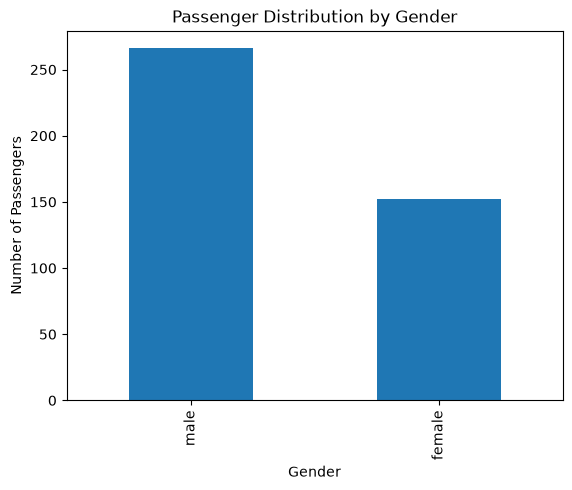

In [17]:
df['Sex'].value_counts().plot(kind='bar')

plt.title('Passenger Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.show()

### Gender Distribution of Titanic Passengers

The bar chart illustrates the distribution of male and female passengers in the Titanic dataset.

**Observations:**

1. Male passengers (266) outnumber female passengers (152).
2. The number of male passengers is considerably higher than the number of female passengers.
3. The dataset contains approximately 63.64% male passengers and 36.36% female passengers.

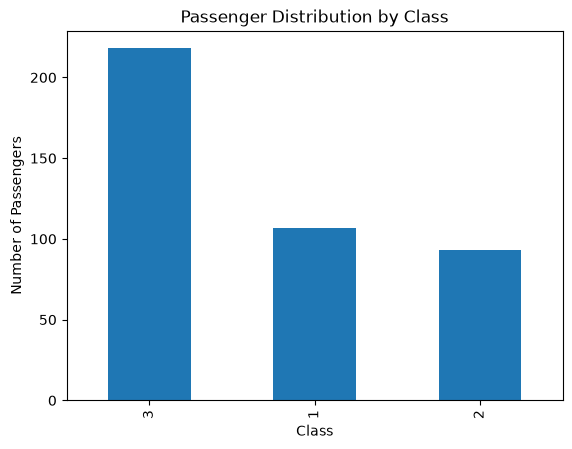

In [18]:
df['Pclass'].value_counts().plot(kind='bar')

plt.title('Passenger Distribution by Class')
plt.xlabel('Class')
plt.ylabel('Number of Passengers')
plt.show()

### Passenger Class Distribution

The bar chart represents the distribution of passengers across the three passenger classes.

**Observations:**

1. Third-class passengers form the largest group, with 218 passengers.
2. First class has 107 passengers.
3. Second class has the lowest number of passengers, with 93 passengers.
4. The distribution indicates that third-class passengers account for the largest share of the dataset.

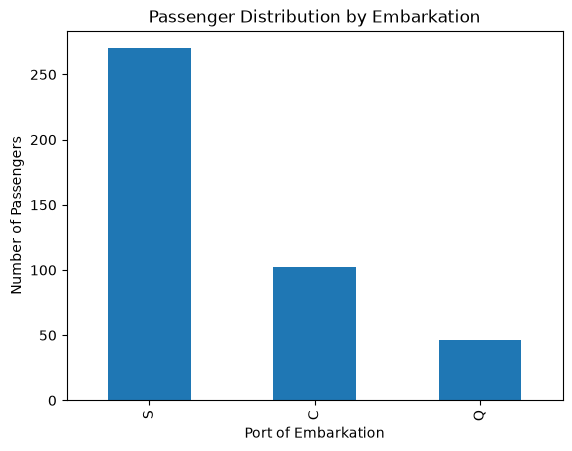

In [19]:
df['Embarked'].value_counts().plot(kind='bar')

plt.title('Passenger Distribution by Embarkation')
plt.xlabel('Port of Embarkation')
plt.ylabel('Number of Passengers')
plt.show()

### Passenger Distribution by Port of Embarkation

The bar chart illustrates the number of passengers who boarded the Titanic from each port.

**Observations:**

1. Southampton (S) had the highest number of passengers (270).
2. Cherbourg (C) had 102 passengers.
3. Queenstown (Q) had the lowest number of passengers (46).
4. Most passengers boarded the Titanic from Southampton.

In [20]:
df['Age'].describe()

count    332.000000
mean      30.272590
std       14.181209
min        0.170000
25%       21.000000
50%       27.000000
75%       39.000000
max       76.000000
Name: Age, dtype: float64

### Observations – Age Statistics

1. The dataset contains 332 non-missing age records out of 418 passengers.
2. The average passenger age is approximately 30.27 years.
3. The median passenger age is 27 years.
4. The youngest passenger was approximately 0.17 years old, while the oldest was 76 years old.
5. The standard deviation is approximately 14.18 years, indicating variation in passenger ages.

### Understanding Mean and Median

- Mean represents the average of all numerical values.
- Median represents the middle value when observations are arranged in ascending order.
- Mean is sensitive to extremely high or low values, whereas median is less affected by them.

**Observation:** In the Titanic dataset, the mean age (30.27 years) is higher than the median age (27 years), suggesting that some higher age values may be pulling the average upwards.

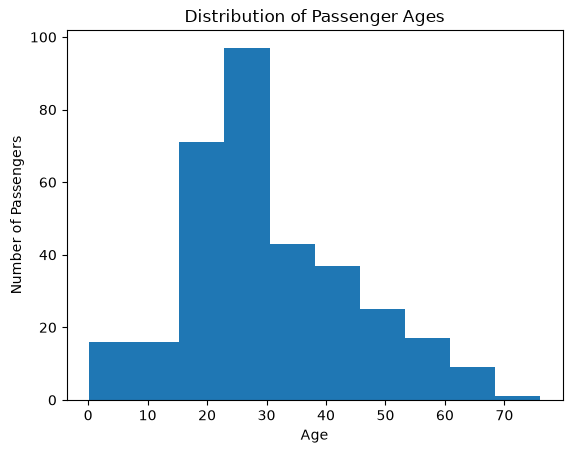

In [21]:
df['Age'].plot(kind='hist', bins=10)

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()

### Age Distribution of Titanic Passengers

The histogram represents the distribution of passenger ages using 10 intervals (bins).

**Observations:**

1. Most passengers were concentrated in the approximate age range of 20–30 years.
2. A considerable number of passengers were between 15 and 35 years old.
3. Passenger frequency generally decreases with increasing age.
4. Very few passengers were above 65 years.
5. The age distribution shows a right-skewed pattern, with a longer tail towards higher ages.

In [22]:
df['Fare'].describe()

count    417.000000
mean      35.627188
std       55.907576
min        0.000000
25%        7.895800
50%       14.454200
75%       31.500000
max      512.329200
Name: Fare, dtype: float64

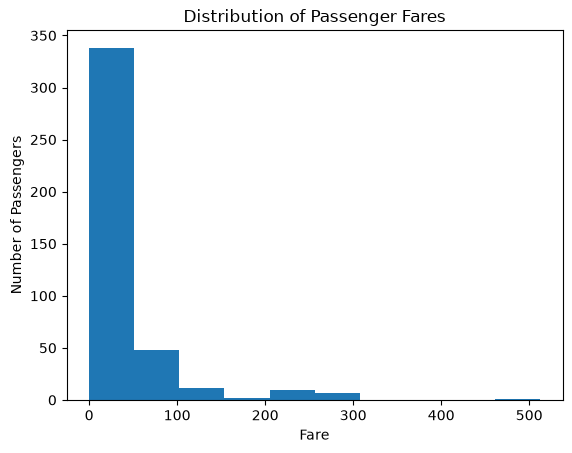

In [23]:
df['Fare'].plot(kind='hist', bins=10)

plt.title('Distribution of Passenger Fares')
plt.xlabel('Fare')
plt.ylabel('Number of Passengers')
plt.show()

### Fare Distribution of Titanic Passengers

The histogram illustrates the distribution of passenger fares using 10 intervals (bins).

**Observations:**

1. Most passengers paid fares in the lower range, approximately between 0 and 35.
2. The frequency of passengers decreases as the fare amount increases.
3. A small number of passengers paid considerably higher fares.
4. The distribution is strongly right-skewed, with a long tail towards higher fare values.
5. Potential outliers are visible at the higher end of the fare distribution.

In [24]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)

In [25]:
IQR = Q3 - Q1

In [26]:
IQR

np.float64(23.6042)

In [27]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -27.5105
Upper Bound: 66.9063


In [28]:
outliers = df[df['Fare'] > upper_bound]

outliers

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
12,904,1,1,"Snyder, Mrs. John Pillsbury (Nelle Stevenson)",female,23.0,1,0,21228,82.2667,B45,S
24,916,1,1,"Ryerson, Mrs. Arthur Larned (Emily Maria Borie)",female,48.0,1,3,PC 17608,262.3750,B57 B59 B63 B66,C
48,940,1,1,"Bucknell, Mrs. William Robert (Emma Eliza Ward)",female,60.0,0,0,11813,76.2917,D15,C
53,945,1,1,"Fortune, Miss. Ethel Flora",female,28.0,3,2,19950,263.0000,C23 C25 C27,S
59,951,1,1,"Chaudanson, Miss. Victorine",female,36.0,0,0,PC 17608,262.3750,B61,C
64,956,0,1,"Ryerson, Master. John Borie",male,13.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
69,961,1,1,"Fortune, Mrs. Mark (Mary McDougald)",female,60.0,1,4,19950,263.0000,C23 C25 C27,S
74,966,1,1,"Geiger, Miss. Amalie",female,35.0,0,0,113503,211.5000,C130,C
75,967,0,1,"Keeping, Mr. Edwin",male,32.5,0,0,113503,211.5000,C132,C
81,973,0,1,"Straus, Mr. Isidor",male,67.0,1,0,PC 17483,221.7792,C55 C57,S


In [29]:
outliers.shape

(55, 12)

In [30]:
(outliers.shape[0] / df.shape[0]) * 100

13.157894736842104

### Percentage of Potential Fare Outliers

**Observations:**

1. A total of 55 passenger records were identified as potential fare outliers using the IQR method.
2. These records represent approximately 13.16% of the dataset.
3. The remaining 86.84% of passenger records fall within the calculated upper and lower boundaries.
4. These unusually high fares require further investigation before deciding whether any data treatment is necessary.

In [31]:
outliers['Pclass'].value_counts()

Pclass
1    49
3     4
2     2
Name: count, dtype: int64

### Investigation of Fare Outliers by Passenger Class

**Observations:**

1. Out of 55 potential fare outliers, 49 belong to First Class.
2. Two potential outliers belong to Second Class.
3. Four potential outliers belong to Third Class.
4. The majority of unusually high fares are associated with First Class passengers.
5. This suggests a possible relationship between passenger class and ticket fare. These values should not be removed without further investigation.

In [32]:
(outliers['Pclass'].value_counts()[1] / len(outliers)) * 100

np.float64(89.0909090909091)

**Additional Observation:**

Approximately 89.09% of the identified potential fare outliers belong to First Class passengers. This suggests that higher ticket fares may be associated with First Class travel. These values should be retained unless further investigation establishes that they are incorrect.

In [33]:
df['SibSp'].value_counts()

SibSp
0    283
1    110
2     14
3      4
4      4
8      2
5      1
Name: count, dtype: int64

### SibSp Distribution – Siblings and Spouses Aboard

The analysis examines the number of siblings and spouses accompanying passengers aboard the Titanic.

**Observations:**

1. A total of 283 passengers had no siblings or spouses aboard.
2. 110 passengers had one sibling or spouse aboard.
3. 14 passengers had two siblings or spouses aboard.
4. Very few passengers had three or more siblings or spouses aboard.
5. Two passengers had eight siblings or spouses aboard.
6. Most passengers in the dataset had no siblings or spouses recorded aboard.

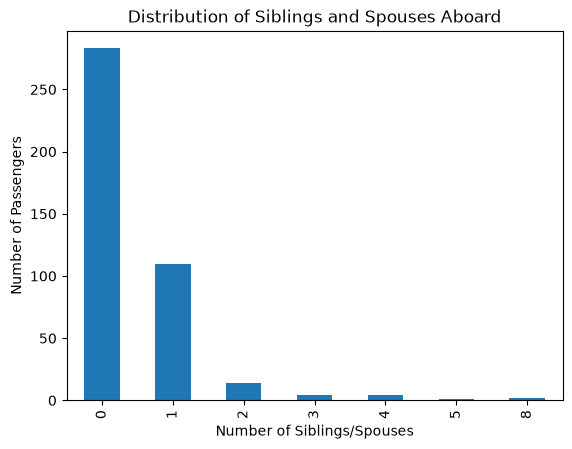

In [34]:
df['SibSp'].value_counts().sort_index().plot(kind='bar')

plt.title('Distribution of Siblings and Spouses Aboard')
plt.xlabel('Number of Siblings/Spouses')
plt.ylabel('Number of Passengers')
plt.show()

### SibSp Distribution – Visualisation

The bar chart illustrates the distribution of passengers based on the number of siblings and spouses travelling aboard the Titanic.

**Observations:**

1. Most passengers (283) had no siblings or spouses aboard.
2. 110 passengers had one sibling or spouse aboard.
3. The number of passengers decreases as the number of siblings or spouses increases.
4. Only a few passengers travelled with larger numbers of siblings or spouses.
5. Overall, the dataset contains a higher number of passengers travelling without siblings or spouses.

In [35]:
df['Parch'].value_counts()

Parch
0    324
1     52
2     33
3      3
4      2
9      2
6      1
5      1
Name: count, dtype: int64

### Parch Distribution – Parents and Children Aboard

The analysis examines the number of parents and children accompanying passengers aboard the Titanic.

**Observations:**

1. A total of 324 passengers had no parents or children aboard.
2. 52 passengers had one parent or child aboard.
3. 33 passengers had two parents or children aboard.
4. Very few passengers had three or more parents or children aboard.
5. One passenger had nine parents or children aboard.
6. Most passengers in the dataset had no parents or children recorded aboard.

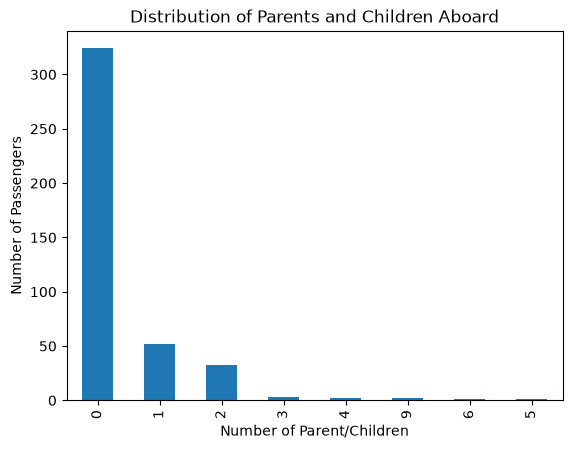

In [36]:
df['Parch'].value_counts().plot(kind='bar')

plt.title('Distribution of Parents and Children Aboard')
plt.xlabel('Number of Parent/Children')
plt.ylabel('Number of Passengers')
plt.show()

### Parch Distribution – Visualisation

The bar chart illustrates the distribution of passengers based on the number of parents and children travelling aboard the Titanic.

**Observations:**

1. The largest group consists of passengers with no parents or children aboard (324 passengers).
2. 52 passengers had one parent or child aboard.
3. 33 passengers had two parents or children aboard.
4. The number of passengers decreases significantly as the number of accompanying parents or children increases.
5. Most passengers had no parents or children recorded aboard.

In [37]:
df['Survived'].value_counts()

Survived
0    266
1    152
Name: count, dtype: int64

### Overall Survival Distribution

The analysis examines the survival status of passengers in the Titanic dataset.

**Observations:**

1. Out of 418 passengers, 266 did not survive.
2. A total of 152 passengers survived.
3. Approximately 63.64% of passengers did not survive.
4. Approximately 36.36% of passengers survived.
5. The dataset contains a higher number of non-survivors than survivors.

In [38]:
df['Survived'].value_counts(normalize=True) * 100

Survived
0    63.636364
1    36.363636
Name: proportion, dtype: float64

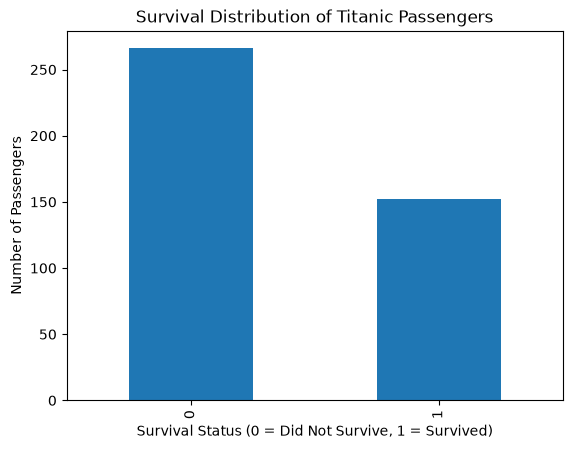

In [39]:
df['Survived'].value_counts().plot(kind='bar')

plt.title('Survival Distribution of Titanic Passengers')
plt.xlabel('Survival Status (0 = Did Not Survive, 1 = Survived)')
plt.ylabel('Number of Passengers')
plt.show()

### Survival Distribution – Visualisation

The bar chart represents the number of passengers who survived and those who did not survive the Titanic disaster.

**Observations:**

1. 266 passengers did not survive.
2. 152 passengers survived.
3. The number of non-survivors is significantly higher than the number of survivors.
4. Approximately 63.64% of passengers did not survive, while 36.36% survived.

In [40]:
pd.crosstab(df['Sex'], df['Survived'])

Survived,0,1
Sex,,
female,0,152
male,266,0


### Survival Analysis by Gender

The cross-tabulation examines the relationship between passenger gender and survival status.

**Observations:**

1. All 152 female passengers survived.
2. All 266 male passengers did not survive.
3. The dataset shows a complete separation in survival outcomes by gender.
4. Gender appears to be strongly associated with survival in this dataset.

In [41]:
pd.crosstab(df['Sex'], df['Survived'], normalize='index') * 100

Survived,0,1
Sex,,
female,0.0,100.0
male,100.0,0.0


### Survival Percentage by Gender

**Observations:**

1. The female survival rate in this dataset is 100%.
2. The male survival rate in this dataset is 0%.
3. All female passengers survived, while all male passengers did not survive.
4. Gender shows a complete separation in survival outcomes in this dataset.

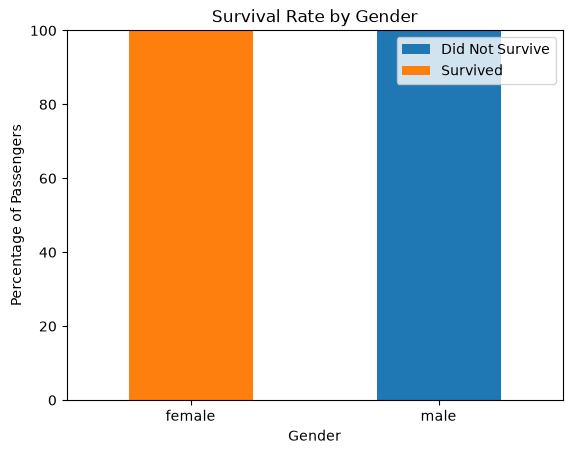

In [42]:
survival_gender = pd.crosstab(df['Sex'], df['Survived'], normalize='index') * 100

survival_gender.plot(kind='bar', stacked=True)

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage of Passengers')
plt.legend(['Did Not Survive', 'Survived'])
plt.xticks(rotation=0)
plt.show()

**Observation: Survival Rate by Gender**

The chart shows that, in this dataset, 100% of female passengers survived, while 100% of male passengers did not survive. This indicates a complete difference in survival outcomes between genders in the dataset.

In [43]:
pd.crosstab(df['Pclass'], df['Survived'])

Survived,0,1
Pclass,,
1,57,50
2,63,30
3,146,72


In [44]:
survival_class = pd.crosstab(
    df['Pclass'],
    df['Survived'],
    normalize='index'
) * 100

survival_class

Survived,0,1
Pclass,,
1,53.271028,46.728972
2,67.741935,32.258065
3,66.972477,33.027523


**Observation: Survival Rate by Passenger Class**

The 1st Class passengers had the highest survival rate at approximately 46.73%, followed by 3rd Class at 33.03% and 2nd Class at 32.26%. Although the highest number of survivors belonged to 3rd Class, the highest survival percentage was observed in 1st Class.

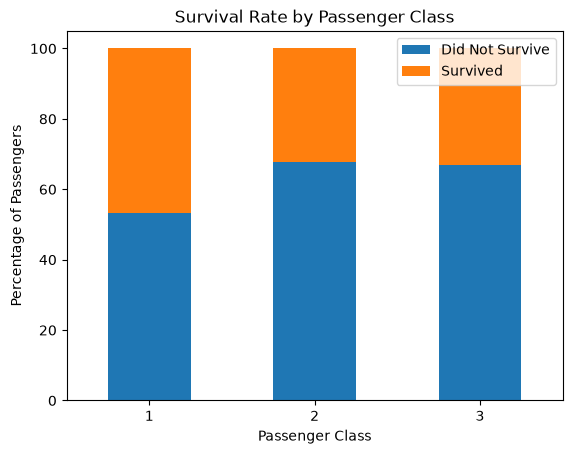

In [45]:
survival_class.plot(kind='bar', stacked=True)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Percentage of Passengers')
plt.legend(['Did Not Survive', 'Survived'])
plt.xticks(rotation=0)
plt.show()

In [46]:
pd.crosstab(df['Embarked'], df['Survived'])

Survived,0,1
Embarked,,
C,62,40
Q,22,24
S,182,88


In [47]:
survival_embarked = pd.crosstab(
    df['Embarked'],
    df['Survived'],
    normalize='index'
) * 100

survival_embarked

Survived,0,1
Embarked,,
C,60.784314,39.215686
Q,47.826087,52.173913
S,67.407407,32.592593


**Observation: Survival Rate by Embarkation Port**

Passengers who embarked at Queenstown had the highest survival rate (52.17%), followed by Cherbourg (39.22%) and Southampton (32.59%). Southampton had the lowest survival rate among the three ports. These results show differences in survival percentages based on embarkation port in this dataset.

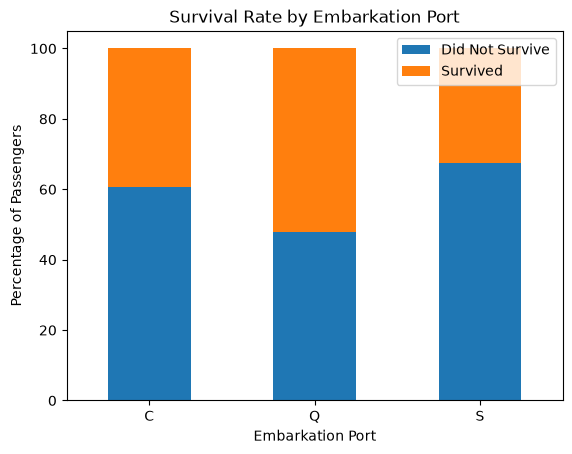

In [48]:
survival_embarked.plot(kind='bar', stacked=True)

plt.title('Survival Rate by Embarkation Port')
plt.xlabel('Embarkation Port')
plt.ylabel('Percentage of Passengers')
plt.legend(['Did Not Survive', 'Survived'])
plt.xticks(rotation=0)
plt.show()

In [49]:
df.groupby('Survived')['Age'].mean()

Survived
0    30.272732
1    30.272362
Name: Age, dtype: float64

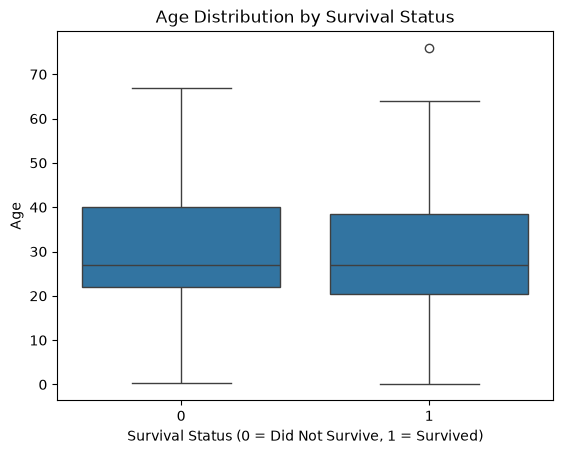

In [50]:
sns.boxplot(x='Survived', y='Age', data=df)

plt.title('Age Distribution by Survival Status')
plt.xlabel('Survival Status (0 = Did Not Survive, 1 = Survived)')
plt.ylabel('Age')
plt.show()

**Observation: Age Distribution by Survival Status**

The box plot shows that the median age of passengers who survived and those who did not survive is approximately the same. Both groups have a similar age distribution, with overlapping ranges. One potential age outlier is visible among the survivors. Based on this dataset, age does not show a clear difference between the two survival groups.

In [51]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 60, 100],
                        labels=['Child', 'Teenager', 'Adult', 'Senior'])

In [52]:
df['AgeGroup'].value_counts()

AgeGroup
Adult       267
Teenager     29
Child        25
Senior       11
Name: count, dtype: int64

In [53]:
df[['Age', 'AgeGroup']].head(10)

,Age,AgeGroup
0,34.5,Adult
1,47.0,Adult
2,62.0,Senior
3,27.0,Adult
4,22.0,Adult
5,14.0,Teenager
6,30.0,Adult
7,26.0,Adult
8,18.0,Teenager
9,21.0,Adult


In [54]:
pd.crosstab(df['AgeGroup'], df['Survived'])

Survived,0,1
AgeGroup,,
Child,13,12
Teenager,17,12
Adult,168,99
Senior,7,4


In [55]:
survival_age = pd.crosstab(
    df['AgeGroup'],
    df['Survived'],
    normalize='index'
) * 100

survival_age

Survived,0,1
AgeGroup,,
Child,52.000000,48.000000
Teenager,58.620690,41.379310
Adult,62.921348,37.078652
Senior,63.636364,36.363636


**Observation: Survival Rate by Age Group**

Children had the highest survival rate at 48%, followed by teenagers at 41.38%, adults at 37.08% and seniors at 36.36%. The results suggest that younger passengers had comparatively higher survival rates in this dataset.

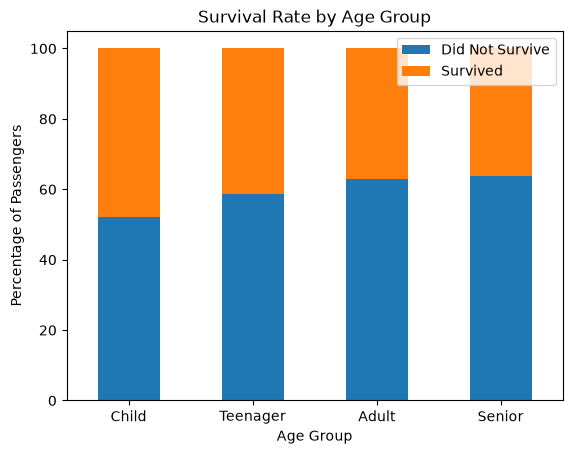

In [56]:
survival_age.plot(kind='bar', stacked=True)

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Percentage of Passengers')
plt.legend(['Did Not Survive', 'Survived'])
plt.xticks(rotation=0)
plt.show()

**Observation: Survival Rate by Age Group**

The chart shows that children had the highest survival rate, while seniors had the lowest. The survival percentage generally decreases across the age groups, suggesting that younger passengers had comparatively better survival outcomes in this dataset.

In [57]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

In [58]:
df[['SibSp', 'Parch', 'FamilySize']].head(10)

,SibSp,Parch,FamilySize
0,0,0,1
1,1,0,2
2,0,0,1
3,0,0,1
4,1,1,3
5,0,0,1
6,0,0,1
7,1,1,3
8,0,0,1
9,2,0,3


In [59]:
df['FamilySize'].value_counts().sort_index()

FamilySize
1     253
2      74
3      57
4      14
5       7
6       3
7       4
8       2
11      4
Name: count, dtype: int64

In [60]:
pd.crosstab(df['FamilySize'], df['Survived'])

Survived,0,1
FamilySize,,
1,185,68
2,38,36
3,27,30
4,4,10
5,5,2
6,1,2
7,3,1
8,1,1
11,2,2


In [61]:
survival_family = pd.crosstab(
    df['FamilySize'],
    df['Survived'],
    normalize='index'
) * 100

survival_family

Survived,0,1
FamilySize,,
1,73.122530,26.877470
2,51.351351,48.648649
3,47.368421,52.631579
4,28.571429,71.428571
5,71.428571,28.571429
6,33.333333,66.666667
7,75.000000,25.000000
8,50.000000,50.000000
11,50.000000,50.000000


**Observation: Survival Rate by Family Size**

Passengers travelling alone had a survival rate of approximately 26.88%, while passengers travelling in family groups of 2, 3 and 4 had higher survival rates. Family size 4 recorded the highest survival rate at 71.43%. However, larger family groups had very few passengers, so their survival percentages should be interpreted cautiously. Overall, travelling with a small family was associated with better survival outcomes in this dataset.

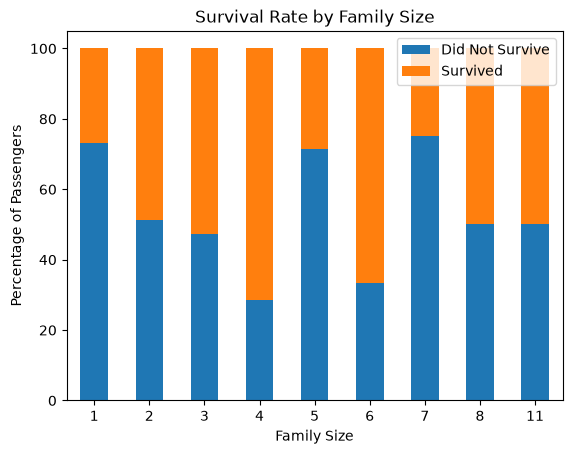

In [62]:
survival_family.plot(kind='bar', stacked=True)

plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Percentage of Passengers')
plt.legend(['Did Not Survive', 'Survived'])
plt.xticks(rotation=0)
plt.show()

**Observation: Survival Rate by Family Size**

The chart indicates that passengers travelling alone had the lowest survival rate (26.88%). Passengers travelling in smaller family groups generally had higher survival percentages, with family size 4 recording the highest rate (71.43%). However, survival percentages for larger family groups should be interpreted cautiously due to their small sample sizes.

In [63]:
df.groupby('Survived')['Fare'].mean()

Survived
0    27.527877
1    49.747699
Name: Fare, dtype: float64

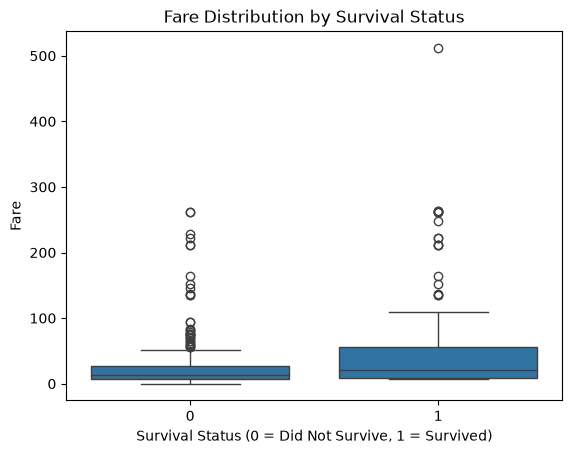

In [64]:
sns.boxplot(x='Survived', y='Fare', data=df)

plt.title('Fare Distribution by Survival Status')
plt.xlabel('Survival Status (0 = Did Not Survive, 1 = Survived)')
plt.ylabel('Fare')
plt.show()

**Observation: Fare Distribution by Survival Status**

The box plot shows that passengers who survived generally had a higher median fare than those who did not survive. The fare distribution among survivors was also more spread out. Both groups contain several high-fare outliers. These findings suggest an association between higher fares and survival outcomes in this dataset.

# Conclusion

The Exploratory Data Analysis of the Titanic dataset helped identify patterns and relationships between passenger characteristics and survival outcomes.

The analysis revealed differences in survival rates based on gender, passenger class, age group, embarkation port, family size and fare.

Some key observations were:

- Female passengers had a higher survival rate than male passengers in this dataset.
- First Class passengers had a higher survival percentage than Second and Third Class passengers.
- Children showed comparatively higher survival rates than older age groups.
- Passengers travelling alone had a lower survival rate than those travelling in smaller family groups.
- Passengers who survived had a higher average fare than those who did not survive.

Overall, the analysis helped demonstrate how Pandas, NumPy, Matplotlib and Seaborn can be used to explore data, identify patterns, investigate outliers and communicate meaningful insights.

**Note:** These findings describe the dataset analysed and should not automatically be generalised to the entire historical Titanic population. Some survival patterns in this dataset are unusually strong and should be interpreted with caution.